# BrainCell vs NEURON: `ExpSyn` and `Exp2Syn`

BrainCell's `ExpSyn` and `Exp2Syn` against NEURON's built-in mechanisms of the same names, on the passive one-segment cylinder of `reference.py` in this directory: an explicit list of event times drives the synapse (BrainCell `EventSequence` through `Network.connect`, NEURON `NetCon(None, syn).event(t)`), fixed step, float64. The automated comparison of the twelve reference scenarios is `reference_test.py`; this notebook plots two of them for inspection.

**Sampling phase.** Sample k of both traces is the state at t = k dt, before the events of that step boundary; an event rounded to step s shows from sample s + 1. NEURON's recorded point-process `i` (and `Exp2Syn.g`) is a `BREAKPOINT` value instead: it already includes the boundary's events, lags the states by one sample and is outward-positive. So the conductance is compared on NEURON's *states* (`g`, or `B - A`) and the current as `g_nrn (e - V_nrn)`, BrainCell's inward-positive convention. Plotted directly, NEURON's own `i` shows the whole jump of an `ExpSyn` event one sample early (the 65 nA spike below): a phase difference, not a dynamics difference.

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import matplotlib.pyplot as plt
import numpy as np


def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in (cwd, *cwd.parents):
        if (candidate / "braincell").exists() and (candidate / "validation").exists():
            return candidate
    raise RuntimeError("Run this notebook from the repository root or a directory inside it.")


repo_root = find_repo_root()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from validation.neuron.synapse.reference import Scenario, run_braincell, run_neuron

exp_syn = Scenario("ExpSyn, one event", "ExpSyn", {"tau": 2.0, "e": 0.0}, (10.0,), 1.0, 40.0)
exp2_syn = Scenario("Exp2Syn, four events", "Exp2Syn", {"tau1": 0.5, "tau2": 5.0, "e": 0.0}, (10.0, 20.0, 30.0, 40.0), 1.0, 50.0)
braincell_traces = run_braincell((exp_syn, exp2_syn))
neuron_traces = {scenario.name: run_neuron(scenario) for scenario in (exp_syn, exp2_syn)}

--No graphics will be displayed.


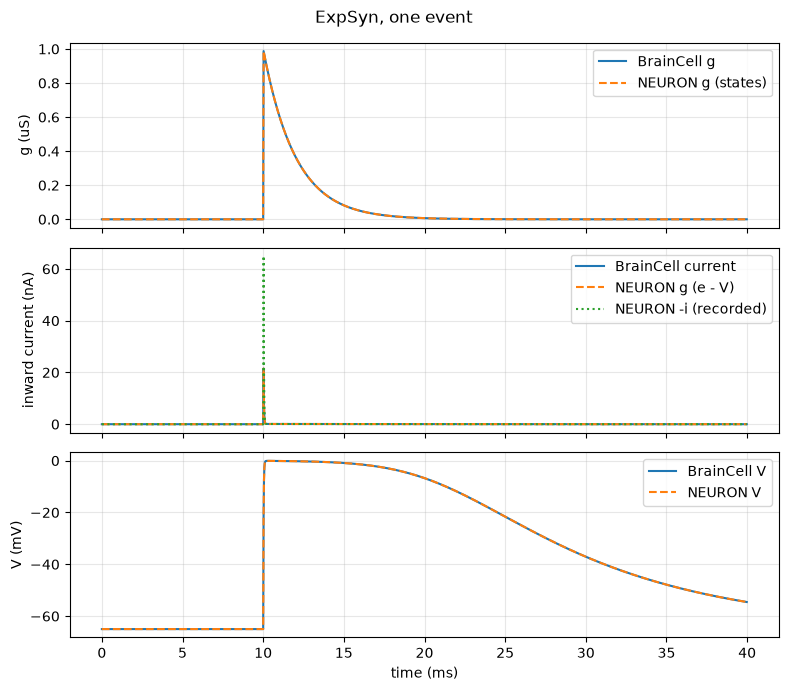

ExpSyn, one event: 1600 samples
  max |dV| = 1.37e-10 mV
  max |dg| = 3.89e-16 uS
  max |di| = 1.36e-10 nA (against g_nrn (e - V_nrn))
  peak current: BrainCell 21.508823 nA, NEURON recorded -i 65.000000 nA


In [2]:
def compare(scenario):
    bc, nrn = braincell_traces[scenario.name], neuron_traces[scenario.name]
    t = bc["time_ms"]
    fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
    axes[0].plot(t, bc["g_uS"], label="BrainCell g")
    axes[0].plot(t, nrn["g_uS"], "--", label="NEURON g (states)")
    axes[0].set_ylabel("g (uS)")
    axes[1].plot(t, bc["i_nA"], label="BrainCell current")
    axes[1].plot(t, nrn["i_nA"], "--", label="NEURON g (e - V)")
    axes[1].plot(t, -nrn["i_recorded_nA"], ":", label="NEURON -i (recorded)")
    axes[1].set_ylabel("inward current (nA)")
    axes[2].plot(t, bc["v_mV"], label="BrainCell V")
    axes[2].plot(t, nrn["v_mV"], "--", label="NEURON V")
    axes[2].set_ylabel("V (mV)")
    axes[2].set_xlabel("time (ms)")
    for axis in axes:
        axis.legend(loc="upper right")
        axis.grid(True, alpha=0.3)
    fig.suptitle(scenario.name)
    fig.tight_layout()
    plt.show()
    print(f"{scenario.name}: {t.size} samples")
    print(f"  max |dV| = {np.max(np.abs(bc['v_mV'] - nrn['v_mV'])):.2e} mV")
    print(f"  max |dg| = {np.max(np.abs(bc['g_uS'] - nrn['g_uS'])):.2e} uS")
    print(f"  max |di| = {np.max(np.abs(bc['i_nA'] - nrn['i_nA'])):.2e} nA (against g_nrn (e - V_nrn))")
    print(f"  peak current: BrainCell {bc['i_nA'].max():.6f} nA, NEURON recorded -i {-nrn['i_recorded_nA'].min():.6f} nA")


compare(exp_syn)

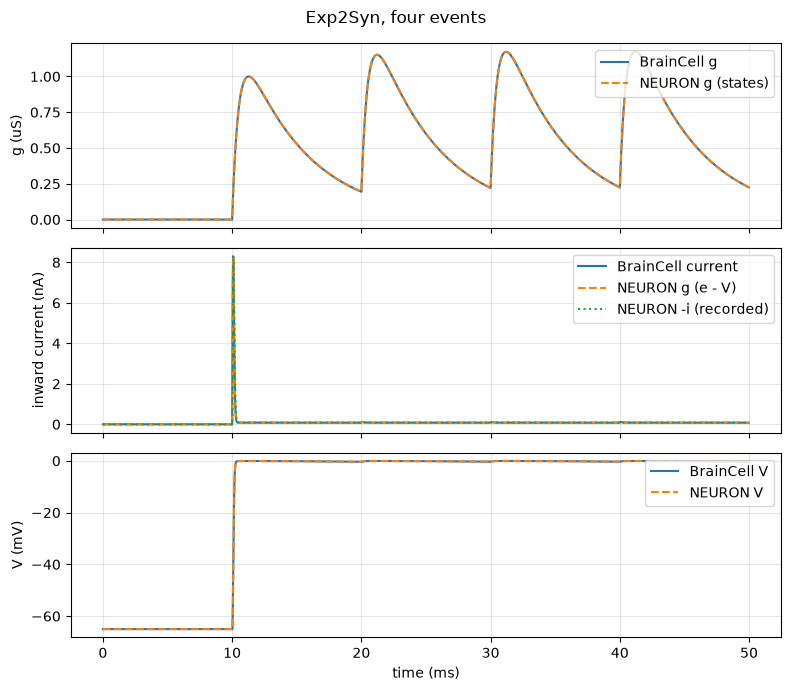

Exp2Syn, four events: 2000 samples
  max |dV| = 2.40e-11 mV
  max |dg| = 1.55e-15 uS
  max |di| = 5.56e-12 nA (against g_nrn (e - V_nrn))
  peak current: BrainCell 8.305458 nA, NEURON recorded -i 8.305458 nA


In [3]:
compare(exp2_syn)